# Assignment_E1

Softmax Classifier: Flatten images into 1D vectors, perform linear mapping, and apply Softmax activation.

MLP Classifier: Multi-layer fully connected network (hidden layers + activation functions) with a Softmax output layer; inputs remain flattened 1D vectors.

CNN Classifier: Convolutional and pooling layers (optional Batch Normalization) followed by a classification head, tailored for small image resolutions.

## Device detection

In [127]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Program using device: {device}")

Program using device: cuda


## User definition

#### Specific infor

In [128]:
# initialize history

## softmax classifier
history_softmax = {"train_loss": [],"train_acc": [],"val_loss": [],"val_acc": []}

result_softmax = {"test_acc": 0.0,"test_loss": 0.0,"train_time": 0.0,"test_time": 0.0,
    "tp": 0,"tn": 0,"fp": 0,"fn": 0,"total_params": 0}

## MLP classifier
history_mlp = {"train_loss": [],"train_acc": [],"val_loss": [],"val_acc": []}

result_mlp = {"test_acc": 0.0,"test_loss": 0.0,"train_time": 0.0,"test_time": 0.0,
    "tp": 0,"tn": 0,"fp": 0,"fn": 0,"total_params": 0}

## CNN classifier
history_cnn = {"train_loss": [],"train_acc": [],"val_loss": [],"val_acc": []}

result_cnn = {"test_acc": 0.0,"test_loss": 0.0,"train_time": 0.0,"test_time": 0.0,
    "tp": 0,"tn": 0,"fp": 0,"fn": 0,"total_params": 0}

In [129]:
# Hyperparameters
batch_size = 32
num_workers = 8

In [130]:
model_softmax_json_path = "./models/softmax.json"
model_mlp_json_path = "./models/mlp.json"
model_cnn_json_path = "./models/cnn.json"

## Helper function

In [131]:
# Test sample model

def helper_test_sample_model(sample_model,dataloader):
    sample_model.eval()

    # Get one real image and its label from CIFAR-10
    images, labels = next(iter(dataloader))

    sample_x = images[0:1].to(device)
    sample_y = labels[0:1].to(device)

    with torch.no_grad():
        result = sample_model(sample_x)
        if isinstance(result, tuple):
            y = result[0]
        else:
            y = result
        y_cls = y.argmax(dim=1)
        y_acc = y_cls.eq(sample_y).sum().item()

    print(f"Model: {sample_model}")
    print(f"Input shape: {sample_x.shape}")
    print(f"Output logits: {y}")
    print(f"Predicted class index: {y_cls.item()}")
    print(f"True class index: {sample_y.item()}")
    print(f"Correct prediction: {bool(y_acc)}")

In [132]:
# Visualization of training and validation history

import matplotlib.pyplot as plt

def helper_plot_history(history, title_prefix="",savepath=None):
    if title_prefix:
        plt.suptitle(title_prefix)

    fig, ax = plt.subplots(2, 2, figsize=(6, 6))

    t_train_loss = history["train_loss"]
    t_train_acc = history["train_acc"]
    t_val_loss = history["val_loss"]
    t_val_acc = history["val_acc"]

    ax[0][0].plot(t_train_loss, label="Train Loss")
    ax[0][0].set_xlabel("Epochs")
    ax[0][0].set_ylabel("Loss")
    ax[0][0].legend()
    ax[0][1].plot(t_train_acc, label="Train Accuracy")
    ax[0][1].set_xlabel("Epochs")
    ax[0][1].set_ylabel("Accuracy")
    ax[0][1].legend()
    ax[1][0].plot(t_val_loss, label="Validation Loss")
    ax[1][0].set_xlabel("Epochs")
    ax[1][0].set_ylabel("Loss")
    ax[1][0].legend()
    ax[1][1].plot(t_val_acc, label="Validation Accuracy")
    ax[1][1].set_xlabel("Epochs")
    ax[1][1].set_ylabel("Accuracy")
    ax[1][1].legend()

    plt.tight_layout()
    plt.show()
    if savepath:
        fig.savefig(savepath)

In [133]:
# Summary model performance with training/validation and test results

def helper_summary_performance(test_pred, history):
    def _helper_time_convert(t):
        minutes = int(t // 60)
        seconds = int(t % 60)
        return minutes, seconds

    train_m, train_s = _helper_time_convert(test_pred['train_time'])
    test_m, test_s = _helper_time_convert(test_pred['test_time'])

    print("Test Performance:")

    print(f"Test Accuracy: {test_pred['test_acc']}")
    print(f"Test Loss: {test_pred['test_loss']}")

    print(f"Min loss of training set = {min(history['train_loss'])}")
    print(f"Min loss of validation set = {min(history['val_loss'])}")
    print(f"Max accuracy of training set = {max(history['train_acc'])}")
    print(f"Max accuracy of validation set = {max(history['val_acc'])}")

    print(f"Train time = {train_m}:{train_s}")
    print(f"Test time = {test_m}:{test_s}")

In [134]:
# Plot capacity and training time comparision

import matplotlib.pyplot as plt

def helper_plot_cap_time(test_preds, model_names, savepath=None):
    fig, ax = plt.subplots(1, 2, figsize=(9, 5))

    colors = ["tab:red", "tab:blue", "tab:green"]

    for i, test_pred in enumerate(test_preds):
        model_name = model_names[i]
        # model_result = test_pred[i]
        color = colors[i]

        param = test_pred['total_params']
        train_time = test_pred['train_time']

        bars_cap = ax[0].bar(model_name, param, color=color)
        ax[0].bar_label(bars_cap, fmt='{:,.0f}', padding=3, fontsize=9)
        ax[0].set_title("Model Capacity")
        ax[0].set_ylabel("Total parameters")

        bars_time = ax[1].bar(model_name, train_time, color=color)
        ax[1].bar_label(bars_time, fmt='{:.2f}s', padding=3, fontsize=9)
        ax[1].set_title("Training Time")
        ax[1].set_ylabel("Time (s)")        

    plt.show()
    if savepath:
        fig.savefig(savepath)

In [135]:
# Plot loss/accuracy of testing set

import matplotlib.pyplot as plt

def helper_plot_testing_result(test_preds, model_names, savepath=None):
    plt.figure(figsize=(12, 5))
    colors = ["tab:red", "tab:blue", "tab:green"]

    for i, test_pred in enumerate(test_preds):
        model_name = model_names[i]
        color = colors[i]
        x_loss = test_pred['test_loss']
        y_acc = test_pred['test_acc']

        if isinstance(x_loss, torch.Tensor):
            x_loss = x_loss.detach().cpu().item() # convert to .cpu to plot
        if isinstance(y_acc, torch.Tensor):
            y_acc = y_acc.detach().cpu().item() # convert to .cpu to plot

        plt.scatter(x_loss, y_acc, label=f"{model_name}", color=color, marker='o')
    plt.title("Testing Result")
    plt.xlabel("Loss")
    plt.ylabel("Accuracy (%)")
    plt.legend()
    if savepath:
        plt.savefig(savepath, dpi=300, bbox_inches='tight')
    plt.show()

In [136]:
# Plot loss/accuracy curve

import matplotlib.pyplot as plt

def helper_plot_curves(histories, model_names, savepath=None):
    fig, ax = plt.subplots(1, 2, figsize=(12, 8))
    colors = ["tab:red", "tab:blue", "tab:green"]

    for i, history in enumerate(histories):
        name = model_names[i]
        color = colors[i]
        ax[0].plot(history['train_loss'], label=f"{name} Train Loss", color=color, linestyle='-')
        ax[0].plot(history['val_loss'], label=f"{name} Val Loss", color=color, linestyle='--')
        ax[1].plot(history['train_acc'], label=f"{name} Train Acc", color=color, linestyle='-')
        ax[1].plot(history['val_acc'], label=f"{name} Val Acc", color=color, linestyle='--')

    ax[0].set_title("Loss")
    ax[0].set_xlabel("Epochs")
    ax[0].set_ylabel("Loss")
    ax[0].legend()

    ax[1].set_title("Accuracy (%)")
    ax[1].set_xlabel("Epochs")
    ax[1].set_ylabel("Accuracy (%)")
    ax[1].legend()

    plt.show()
    if savepath:
        fig.savefig(savepath)

In [137]:
# Visualize confusion matrix

import seaborn as sns
import matplotlib.pyplot as plt

def helper_plot_cm(cms, model_names, savepath=None):
    fig, ax = plt.subplots(1, len(cms), figsize=(21, 9), squeeze=False)

    for i, cm in enumerate(cms):
        ax[0, i].set_title(model_names[i])
        ax[0, i] = cm.plot(ax=ax[0, i])
    if savepath:
        fig.savefig(savepath)

In [138]:
def helper_extract_tp_tn_fp_fn(cms, predictions):
    import pandas as pd
    import numpy as np

    cm_pds = []
    for cm, pred in zip(cms, predictions):
        cm = cm.compute()
        TP = cm.diag()
        FP = cm.sum(dim=0) - TP
        FN = cm.sum(dim=1) - TP
        TN = cm.sum() - (TP + FP + FN)
        precision = TP / (TP+FP)
        precision = precision.detach().cpu().numpy()
        recall = TP/(TP+FN)
        recall = recall.detach().cpu().numpy()
        f1_score = 2 * TP / (2 * TP + FP + FN)
        f1_score = f1_score.detach().cpu().numpy()
        marco_precision = np.average(precision)
        marco_recall = np.average(recall)
        marco_f1 = np.average(f1_score)

        cm_pd = pd.DataFrame({
            'Class' : [i for i in range(len(TP))],
            'TP': TP.cpu(),
            'TN': TN.cpu(),
            'FP': FP.cpu(),
            'FN': FN.cpu(),
            'precision' : precision,
            'recall' : recall,
            'F1_Score': f1_score
        })

        pred['tp'] = TP.cpu()
        pred['tn'] = TN.cpu()
        pred['fp'] = FP.cpu()
        pred['fn'] = FN.cpu()
        pred['marco_precision'] = marco_precision
        pred['marco_recall'] = marco_recall
        pred['marco_f1'] = marco_f1

        cm_pds.append(cm_pd)
    return cm_pds

In [139]:
def clean_for_json(obj):
    import numpy as np
    if isinstance(obj, torch.Tensor):
        if obj.numel() == 1:       
            return obj.item()      
        return obj.detach().cpu().tolist()  

    if isinstance(obj, (np.generic, np.number)):
        return obj.item()

    if isinstance(obj, np.ndarray):
        return obj.tolist()

    if isinstance(obj, dict):
        return {k: clean_for_json(v) for k, v in obj.items()}

    if isinstance(obj, list):
        return [clean_for_json(v) for v in obj]

    return obj

def helper_replace2json(file_path, keygroup, data):
    import json
    existing_data = {}
    if os.path.exists(file_path) and os.path.getsize(file_path) > 0:
        with open(file_path, 'r', encoding='utf-8') as f:
            try:
                existing_data = json.load(f)
            except json.JSONDecodeError:
                existing_data = {}
    
    existing_data[keygroup] = data
    
    with open(file_path, 'w', encoding='utf-8') as f:
        json.dump(existing_data, f, indent=4, ensure_ascii=False)

def helper_get_value_json(file_path, keygroup):
    import json
    with open(file_path, 'r', encoding='utf-8') as f:
        data = json.load(f, encoding='utf-8')
    
    return data.get(keygroup, {})

## Dataset

Name: CIFAR-10

Source: torchvision

Total sample: 60000 color images

        + Training Set: 50000 images (5000 images per class)

        + Test Set: 10000 images (1000 images per class)

Data input: raw shape (32, 32, 3)

Class (10): airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck

### Download dataset

Download dataset from torchvision library

In [140]:
# Define transformations for the dataset
## .ToTensor() :  convert a value of pixel from [0, 255] to [0, 1]

import os
import torchvision
import torchvision.transforms as transforms

# Get dataset

if not os.path.exists('../data'):
    train_dataset = torchvision.datasets.CIFAR10(
        root='../data', 
        train=True, 
        download=True, 
        transform=transforms.ToTensor()
    )

    test_dataset = torchvision.datasets.CIFAR10(
        root='../data', 
        train=False, 
        download=True, 
        transform=transforms.ToTensor()
    )
else:
    train_dataset = torchvision.datasets.CIFAR10(
        root='../data', 
        train=True, 
        download=False, 
        transform=transforms.ToTensor()
    )

    test_dataset = torchvision.datasets.CIFAR10(
        root='../data', 
        train=False, 
        download=False, 
        transform=transforms.ToTensor()
    )

Analyze dataset

In [141]:
input_image_size = train_dataset[0][0].size()
num_class = len(train_dataset.classes)
print(f"Input image size: {input_image_size}")
print(f"Sample of image = {train_dataset[0][0]}")
print(f"Number of classes: {num_class}")
print(f"Label = {train_dataset.classes}")

global_class = train_dataset.classes

Input image size: torch.Size([3, 32, 32])
Sample of image = tensor([[[0.231373, 0.168627, 0.196078,  ..., 0.619608, 0.596078, 0.580392],
         [0.062745, 0.000000, 0.070588,  ..., 0.482353, 0.466667, 0.478431],
         [0.098039, 0.062745, 0.192157,  ..., 0.462745, 0.470588, 0.427451],
         ...,
         [0.815686, 0.788235, 0.776471,  ..., 0.627451, 0.219608, 0.207843],
         [0.705882, 0.678431, 0.729412,  ..., 0.721569, 0.380392, 0.325490],
         [0.694118, 0.658824, 0.701961,  ..., 0.847059, 0.592157, 0.482353]],

        [[0.243137, 0.180392, 0.188235,  ..., 0.517647, 0.490196, 0.486275],
         [0.078431, 0.000000, 0.031373,  ..., 0.345098, 0.325490, 0.341176],
         [0.094118, 0.027451, 0.105882,  ..., 0.329412, 0.329412, 0.286275],
         ...,
         [0.666667, 0.600000, 0.631373,  ..., 0.521569, 0.121569, 0.133333],
         [0.545098, 0.482353, 0.564706,  ..., 0.580392, 0.243137, 0.207843],
         [0.564706, 0.505882, 0.556863,  ..., 0.721569, 0.46274

### Split training dataset

Split data set to 80% for training and 20% for validation

In [142]:
# Split training dataset into training and validation sets
import torch
from torch.utils.data import random_split

tr_ratio = 0.8

train_size = int(tr_ratio * len(train_dataset))
val_size = len(train_dataset) - train_size
train_splitset, val_splitset = random_split(train_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(3))

print(f"Training dataset size: {len(train_splitset)}")
print(f"Validation dataset size: {len(val_splitset)}")

Training dataset size: 40000
Validation dataset size: 10000


Subset Train: Counter({7: 4033, 0: 4021, 9: 4016, 2: 4000, 6: 3996, 1: 3995, 5: 3993, 8: 3991, 3: 3989, 4: 3966})
Subset Validation: Counter({4: 1034, 3: 1011, 8: 1009, 5: 1007, 1: 1005, 6: 1004, 2: 1000, 9: 984, 0: 979, 7: 967})
Subset Test: Counter({3: 1000, 8: 1000, 0: 1000, 6: 1000, 1: 1000, 9: 1000, 5: 1000, 7: 1000, 4: 1000, 2: 1000})


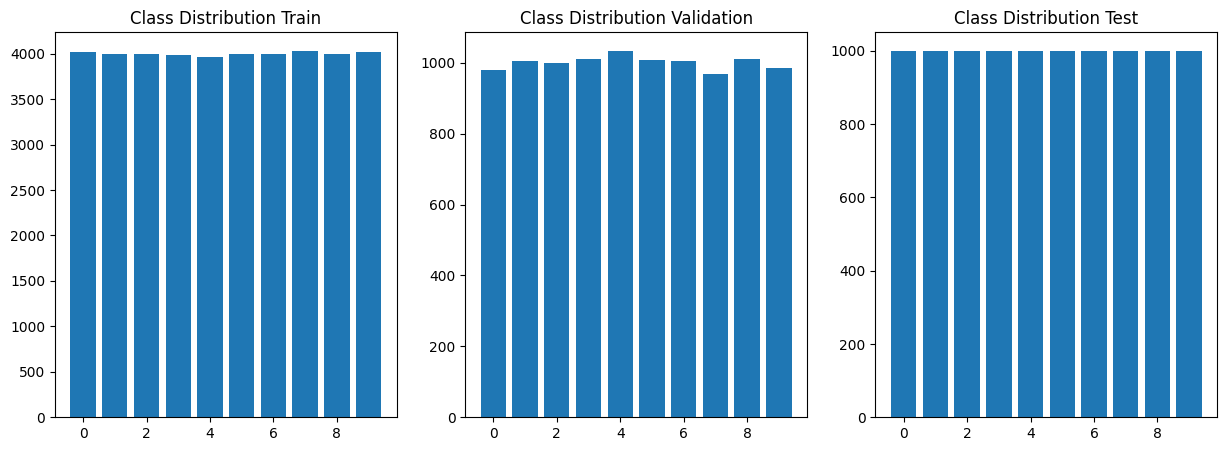

In [143]:
from collections import Counter
from matplotlib import pyplot as plt
import numpy as np

fig, ax = plt.subplots(1,3, figsize=(15,5))

for i, subfolder in enumerate([train_splitset, val_splitset, test_dataset]):
    label_counts = Counter(label for _, label in subfolder)
    labels, counts = zip(*label_counts.items())
    ax[i].bar(labels, counts)
    ax[i].set_title(f'Class Distribution {["Train", "Validation", "Test"][i]}')
    print(f"Subset {['Train', 'Validation', 'Test'][i]}: {label_counts}")


plt.savefig("./models/label_distribution.png")
plt.show()


### Visualize dataset

Visualize sample of dataset

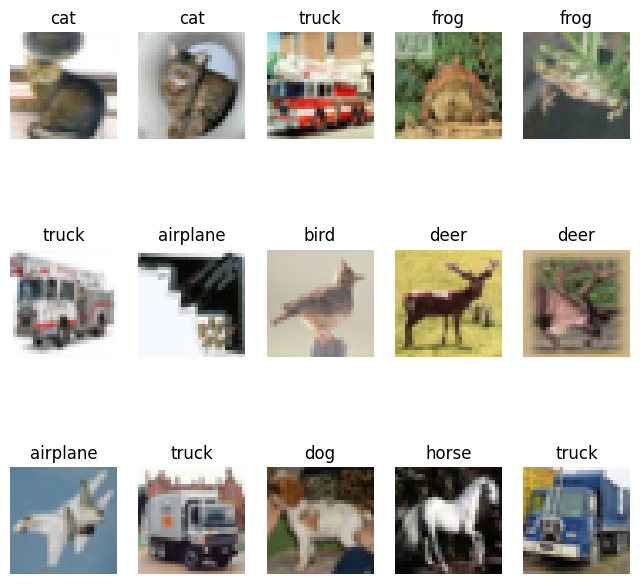

In [144]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(3, 5, figsize=(8, 8))
ax = ax.flatten()

for i in range(5):
    img, label = train_splitset[i]
    ax[i].imshow(img.permute(1, 2, 0))
    ax[i].set_title(train_splitset.dataset.classes[label])
    ax[i].axis('off')
for j in range(5, 10):
    img, label = val_splitset[j]
    ax[j].imshow(img.permute(1, 2, 0))
    ax[j].set_title(val_splitset.dataset.classes[label])
    ax[j].axis('off')
for k in range(10, 15):
    img, label = test_dataset[k]
    ax[k].imshow(img.permute(1, 2, 0))
    ax[k].set_title(test_dataset.classes[label])
    ax[k].axis('off')
plt.show()

### Transform dataset

Normalizing CIFAR-10 images scales pixel values to [-1, 1], centers the data distribution around zero, speeds up Gradient Descent convergence, and stabilizes training across layers

In [145]:
# normalization to [-1, 1] from [0, 1]

import torchvision.transforms as transforms

transform_cifar = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

print(f"Sample before normalization: {train_splitset[4][0]}")

train_splitset.dataset.transform = transform_cifar
val_splitset.dataset.transform = transform_cifar
test_dataset.transform = transform_cifar

print(f"Sample after normalization: {train_splitset[4][0]}")

Sample before normalization: tensor([[[0.474510, 0.474510, 0.474510,  ..., 0.494118, 0.435294, 0.474510],
         [0.447059, 0.439216, 0.447059,  ..., 0.517647, 0.411765, 0.450980],
         [0.411765, 0.411765, 0.431373,  ..., 0.525490, 0.439216, 0.462745],
         ...,
         [0.239216, 0.262745, 0.266667,  ..., 0.258824, 0.243137, 0.231373],
         [0.254902, 0.274510, 0.274510,  ..., 0.250980, 0.231373, 0.223529],
         [0.274510, 0.278431, 0.274510,  ..., 0.250980, 0.231373, 0.223529]],

        [[0.439216, 0.439216, 0.439216,  ..., 0.490196, 0.556863, 0.592157],
         [0.423529, 0.411765, 0.419608,  ..., 0.498039, 0.486275, 0.478431],
         [0.396078, 0.396078, 0.419608,  ..., 0.509804, 0.509804, 0.470588],
         ...,
         [0.219608, 0.223529, 0.239216,  ..., 0.286275, 0.298039, 0.298039],
         [0.227451, 0.223529, 0.239216,  ..., 0.278431, 0.290196, 0.290196],
         [0.235294, 0.215686, 0.227451,  ..., 0.278431, 0.286275, 0.290196]],

        [[0.407

### DataLoader

In [146]:
# DataLoader

import torch

train_loader = torch.utils.data.DataLoader(
    train_splitset, 
    batch_size=batch_size, 
    shuffle=True,
    num_workers=num_workers,
    pin_memory=True
)

val_loader = torch.utils.data.DataLoader(
    val_splitset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=True
)

test_loader = torch.utils.data.DataLoader(
    test_dataset, 
    batch_size=batch_size, 
    shuffle=False,
    num_workers=num_workers,
    pin_memory=True
)

## Cross Entropy Loss by torch

Loss function:
- Cross entropy is used to measure the difference between the true label distribution and the predicted probability distribution:
  L = - Σ y_i log(p_i)
- In the case of integer labels (from 0 to 9), sparse categorical cross entropy is applied:
  L = -log(p_correct_class) means one-hot label result is use to calculate loss
- Cross entropy strongly penalizes incorrect predictions with high confidence. It is suitable for softmax-based multi-class classification problems

In [147]:
# Prove that CrossEntropyLoss is equivalent to LogSoftmax + NLLLoss (negative log likelihood) in PyTorch

import torch
import torch.nn as nn

# create sample logits and labels
logits = torch.tensor([[2.0, 1.0, 0.1]]) # batch size = 1, 3 classes
label = torch.tensor([0])               # batch size = 1, correct class is 0

# Case 1 : using nn.CrossEntropyLoss (Softmax + NLLLoss)
ce_lossfunc = nn.CrossEntropyLoss()
ce_loss = ce_lossfunc(logits, label)

# Case 2 : manual calculate
## logits -> log(softmax) -> NLLLoss
logit_softmax = nn.LogSoftmax(dim=1)
nllloss = nn.NLLLoss()
logit_prob = logit_softmax(logits) # probability after softmax
logit_softmax_loss = nllloss(logit_prob, label)

# case 3 : calculate loss directly from logits without using Softmax
logit_loss = nllloss(logits, label)

# print result
print(f"using nn.CrossEntropyLoss : {ce_loss.item():.6f}")
print(f"manually (LogSoftmax + nn.NLLLoss) : {logit_softmax_loss.item():.6f}")
print(f"manually nn.NLLLoss : {logit_loss.item():.6f}")

# Conclusion:
if ce_loss.item() == logit_softmax_loss.item() and ce_loss.item() != logit_loss.item():
    print("CrossEntropyLoss is equivalent to LogSoftmax + NLLLoss")
else:
    print("nn.CrossEntropyLoss is NOT equivalent to manually (LogSoftmax + NLLLoss)")

using nn.CrossEntropyLoss : 0.417030
manually (LogSoftmax + nn.NLLLoss) : 0.417030
manually nn.NLLLoss : -2.000000
CrossEntropyLoss is equivalent to LogSoftmax + NLLLoss


SGD (Stochastic Gradient Descent) is an optimization algorithm that updates network weights iteratively based on the gradient of the loss function computed from a small batch of data

Combined with Momentum to accelerate learning in relevant directions and reduce oscillations across steep ravines. LR (Learning Rate) determines the step size taken towards the minimum at each iteration, where a higher initial value enables faster initial feature exploration. Set the LR large in first training then apply Cosine Annealing LR Scheduler that decreases the learning rate from an initial value to a minimum value following a half‑cosine curve over T_max iterations

Weight Decay applies L2 regularization by penalizing large weights to reduce overfitting and improve model generalization

In [148]:
class modelOptimizer():
    def __init__(self, model, lr):
        self.model = model
        self.lr = lr
        self.optimizer = torch.optim.SGD(self.model.parameters(), lr=self.lr, momentum=mm, weight_decay=weight_decay)
        # self.scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(self.optimizer, T_max=T_max, eta_min=eta_min)
        self.scheduler = torch.optim.lr_scheduler.StepLR(self.optimizer, step_size=step_size, gamma=gamma)
    def zero_grad(self):
        self.optimizer.zero_grad(set_to_none=True)

    def step(self):
        self.optimizer.step()
    
    def scheduler_step(self):
        self.scheduler.step()

## [1] - Softmax classifier

### Model preparation

Layer (type:depth-idx)                   Output Shape              Param #

SoftmaxClassifierDefinition              [64, 10]                  --

├─Flatten: 1-1                           [64, 3072]                --

├─Linear: 1-2                            [64, 10]                  30,730

In [149]:
# define Softmax classifier
## create default input dimension and number of classes for CIFAR-10 dataset (32x32x3 images, 10 classes)
## flatten the input image into a vector (32x32x3 = 3072)
## forward pass will flatten the input and apply the linear layer from input_dim to num_classes
## return the output of the linear layer after flattening the input (num_classes)

import torch.nn as nn

class SoftmaxClassifierDefinition(nn.Module):
    def __init__(self, input_dim=3072, num_classes=10):
        super(SoftmaxClassifierDefinition, self).__init__()
        self.flatten = nn.Flatten()
        self.linear = nn.Linear(input_dim, num_classes)

    def forward(self, x): # Pytorch package requires defining the forward pass and __call__ method will call this forward method automatically
        x = self.flatten(x)
        x_linear = self.linear(x)
        return x_linear

In [150]:
# Initialize loss function and optimizer for the model
from torchmetrics.classification import Accuracy, ConfusionMatrix

model_softmax_loss_func = nn.CrossEntropyLoss() # nn.CrossEntropyLoss combines LogSoftmax and NLLLoss
accuracy_softmax = Accuracy(task="multiclass", num_classes=num_class).to(device)
cm_softmax = ConfusionMatrix(task="multiclass", num_classes=num_class).to(device)

### Load model

In [151]:
# Initialize model
model_softmax_best = SoftmaxClassifierDefinition().to(device) # create a new instance of the model
model_softmax_last = SoftmaxClassifierDefinition().to(device) # create a new instance of the model

result_softmax['total_params'] = sum(p.numel() for p in model_softmax_best.parameters())
print("Parameters:", result_softmax['total_params'])

Parameters: 30730


In [152]:
# Load the best and last model checkpoints
checkpoint_best = torch.load("./models/best_softmaxcls_model.pth")
model_softmax_best.load_state_dict(checkpoint_best['model_state_dict']) # load the best model weights

checkpoint_last = torch.load("./models/last_softmaxcls_model.pth")
model_softmax_last.load_state_dict(checkpoint_last['model_state_dict']) # load the last model weights

C:\Users\pla2hc\AppData\Local\Temp\ipykernel_23276\2080682398.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint_best = torch.load("./models/best_softmaxcls_mode

<All keys matched successfully>

In [153]:
## Testing with best model
model_softmax_best.eval() # enable evaluation mode

SoftmaxClassifierDefinition(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear): Linear(in_features=3072, out_features=10, bias=True)
)

In [154]:
history_softmax = checkpoint_last['history']

<Figure size 640x480 with 0 Axes>

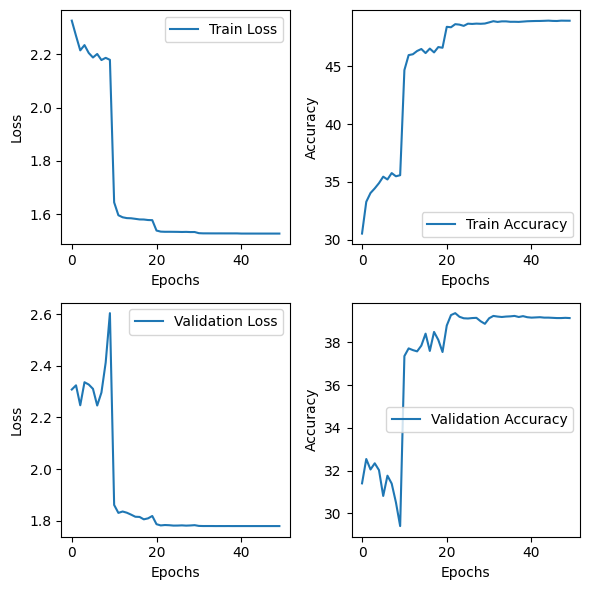

In [155]:
# Visualization of training and validation history

helper_plot_history(history_softmax, title_prefix="Softmax classifier", savepath="./models/history_softmax.png")

### Execute testing

In [156]:
# Testing phase
## test_loss_total : loss calculated on total test samples for the current epoch
## test_sample_total : total number of test samples for the current epoch
## test_loss_mean_batch : loss calculated for the current test batch
## test_softmax_loss_epoch : calculate the average loss for the current epoch
## test_softmax_acc_epoch : calculate the accuracy for the current epoch

import time

test_loss_total, test_sample_total = 0.0, 0.0
test_loss_mean_batch = 0.0

test_preds = []
act_preds = []

start_time = time.time()
with torch.no_grad():
    for batch_idx, (inputs, targets) in enumerate(test_loader):
        inputs, targets = inputs.to(device), targets.to(device)

        output_z = model_softmax_best(inputs) # input => softmax classifier => output logits z

        test_loss_mean_batch = model_softmax_loss_func(output_z, targets)

        test_loss_total += test_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
        predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
        test_sample_total += targets.size(0)
        test_preds.append(predicted.to(device))
        act_preds.append(targets.to(device))

end_test_time = time.time()
result_softmax['test_time'] = end_test_time - start_time
result_softmax['test_loss'] = test_loss_total / test_sample_total
result_softmax['test_acc'] = accuracy_softmax(torch.cat(test_preds), torch.cat(act_preds))*100
cm_softmax(torch.cat(test_preds), torch.cat(act_preds))

print(f"[test_loss = {result_softmax['test_loss']:.4f}] [test_acc = {result_softmax['test_acc']:.2f}%]")

[test_loss = 1.7799] [test_acc = 38.63%]


### Evaluation

Evaluation method:

        Train accuracy

        Validation accuracy

        Testing accuracy

        Traing time

In [157]:
# Visualize model performance

helper_summary_performance(result_softmax, history_softmax)

Test Performance:
Test Accuracy: 38.630001068115234
Test Loss: 1.7799377323150636
Min loss of training set = 1.5276080810546875
Min loss of validation set = 1.7795174306869508
Max accuracy of training set = 48.97
Max accuracy of validation set = 39.37
Train time = 0:0
Test time = 0:19


In [158]:
helper_replace2json(model_softmax_json_path, 'result', clean_for_json(result_softmax))
helper_replace2json(model_softmax_json_path, 'history', clean_for_json(history_softmax))

## [2] - Multiple layer perceptron

### Model preparation

- Input layer (H, W, C): (32, 32, 3)
- Flatten layer: Converts input image into a 3072-dimensional vector
- Dense layer 1:
  - 256 neurons, ReLU activation
  - Parameters: (3072 × 256) + 256 = 786688
- Dense layer 2:
  - 128 neurons, ReLU activation
  - Parameters: (256 × 128) + 128 = 32896
- Dense layer 3:
  - 64 neurons, ReLU activation
  - Parameters: (128 × 64) + 64 = 8256
- Dense layer 4:
  - 32 neurons, ReLU activation
  - Parameters: (64 × 32) + 32 = 2080
- Output layer:
  - 10 neurons, Softmax activation
  - Parameters: (32 × 10) + 10 = 330
- Total trainable parameters:
  - 786688 + 32896 + 8256 + 2080 + 330 = 830250

Review output layer:
- Dense(10, activation='softmax')
- Softmax converts raw logits into probabilities:
  p_i = exp(z_i) / Σ exp(z_j)
- The output is a vector of 10 probabilities corresponding to 10 classes (from 0 to 9),
  where the sum of all probabilities equals 1.
- The maximum value of them corresponding to prediction result of model with input

In [159]:
import torch.nn as nn

class MulLayerPer(nn.Module):
    def __init__(self, input_dim=3072, num_perceptron_layer=[256, 128, 64, 32], num_cls = 10):
        super(MulLayerPer, self).__init__()
        self.flatten = nn.Flatten()
        self.layers = nn.ModuleList()
        in_features = input_dim
        for out_features in num_perceptron_layer:
            self.layers.append(nn.Linear(in_features, out_features))
            self.layers.append(nn.ReLU())
            in_features = out_features
        self.layers.append(nn.Linear(in_features, num_cls))

    def forward(self, x):
        return self._forward_impl(x)

    def _forward_impl(self, x):
        out = self.flatten(x)
        for layer in self.layers:
            out = layer(out)
        return out

In [160]:
# Initialize loss function and optimizer for the model
from torchmetrics.classification import Accuracy, ConfusionMatrix

accuracy_mlp = Accuracy(task="multiclass", num_classes=num_class).to(device)
cm_mlp = ConfusionMatrix(task="multiclass", num_classes=num_class).to(device)
model_mlp_loss_func = nn.CrossEntropyLoss() # nn.CrossEntropyLoss combines LogSoftmax and NLLLoss

### Load model

In [161]:
# Initialize model
model_mlp_best = MulLayerPer(
    input_dim=3072, 
    num_perceptron_layer=[256, 128, 64, 32], 
    num_cls=10
).to(device) # create a new instance of the model
model_mlp_last = MulLayerPer(
    input_dim=3072, 
    num_perceptron_layer=[256, 128, 64, 32], 
    num_cls=10
).to(device) # create a new instance of the model

result_mlp['total_params'] = sum(p.numel() for p in model_mlp_best.parameters())
print("Parameters:", result_mlp['total_params'])

Parameters: 830250


In [162]:
import torch

checkpoint = torch.load("./models/best_mlp_model.pth") # load the best model checkpoint
model_mlp_best.load_state_dict(checkpoint['model_state_dict']) # load the best model weights
checkpoint_last = torch.load("./models/last_mlp_model.pth") # load the last model checkpoint
model_mlp_last.load_state_dict(checkpoint_last['model_state_dict']) # load the last model weights

C:\Users\pla2hc\AppData\Local\Temp\ipykernel_23276\3525555688.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load("./models/best_mlp_model.pth") # lo

<All keys matched successfully>

In [163]:
## Testing with best model
model_mlp_best.eval() # enable evaluation mode

MulLayerPer(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers): ModuleList(
    (0): Linear(in_features=3072, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): ReLU()
    (8): Linear(in_features=32, out_features=10, bias=True)
  )
)

In [164]:
history_mlp = checkpoint_last['history']

<Figure size 640x480 with 0 Axes>

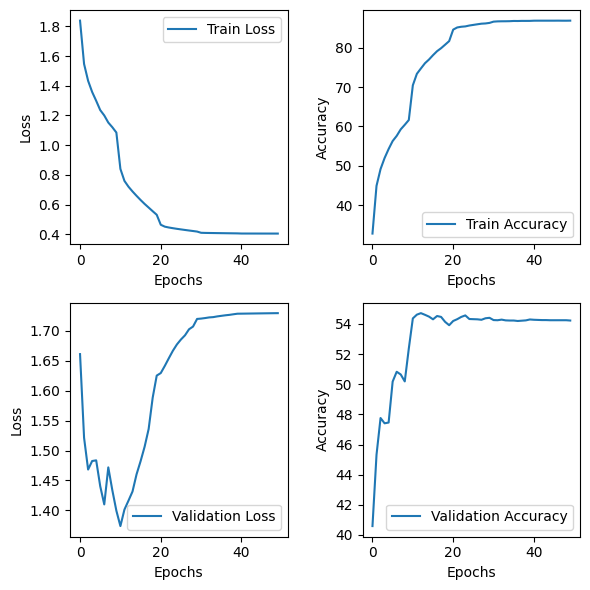

In [165]:
# Visualization of training and validation history

helper_plot_history(history_mlp, title_prefix="MLP classifier", savepath="./models/history_mlp.png")

### Execute testing

In [166]:
# Testing phase
## test_loss_total : loss calculated on total test samples for the current epoch
## test_sample_total : total number of test samples for the current epoch
## test_loss_mean_batch : loss calculated for the current test batch
## test_mlp_loss_epoch : calculate the average loss for the current epoch
## test_mlp_acc_epoch : calculate the accuracy for the current epoch
test_loss_total, test_sample_total = 0.0, 0.0
test_loss_mean_batch = 0.0

test_preds = []
act_preds = []

start_time = time.time()
with torch.no_grad():
    for batch_idx, (inputs, targets) in enumerate(test_loader):
        inputs, targets = inputs.to(device), targets.to(device)

        output_z = model_mlp_best(inputs) # input => MLP => output logits z

        test_loss_mean_batch = model_mlp_loss_func(output_z, targets)

        test_loss_total += test_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
        predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
        test_sample_total += targets.size(0)
        test_preds.append(predicted.to(device))
        act_preds.append(targets.to(device))

end_test_time = time.time()
result_mlp['test_time'] = end_test_time - start_time
result_mlp['test_loss'] = test_loss_total / test_sample_total
result_mlp['test_acc'] = accuracy_mlp(torch.cat(test_preds), torch.cat(act_preds))*100
cm_mlp(torch.cat(test_preds), torch.cat(act_preds))

print(f"[test_loss = {result_mlp['test_loss']:.4f}] [test_acc = {result_mlp['test_acc']:.2f}%]")

[test_loss = 1.3989] [test_acc = 55.23%]


### Evaluation

In [167]:
# Visualize model performance

helper_summary_performance(result_mlp, history_mlp)

Test Performance:
Test Accuracy: 55.22999572753906
Test Loss: 1.3989187940597534
Min loss of training set = 0.40483479247689247
Min loss of validation set = 1.3739398162841796
Max accuracy of training set = 86.905
Max accuracy of validation set = 54.72
Train time = 0:0
Test time = 0:21


In [168]:
helper_replace2json(model_mlp_json_path, 'result', clean_for_json(result_mlp))
helper_replace2json(model_mlp_json_path, 'history', clean_for_json(history_mlp))

## [3] - CNN

### Model preparation

pipeline: input => Conv2D => BatchNorm => ReLU => output of layer

In [169]:
import torch.nn as nn
import torch.nn.functional as F

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, padding, stride):
        super().__init__()

        # using nn.Conv2d will init kernel/weight and bias
        self.conv = nn.Conv2d(in_ch, out_ch, kernel_size, stride, padding)
        self.bn = nn.BatchNorm2d(out_ch)

    # define a forward pipeline with: Conv2D => BatchNorm => ReLU
    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        x = F.relu(x)
        return x

In [170]:
KERNEL_SIZE_3 = 3
PADDING_SIZE_1 = 1
STRIDE_SIZE_1 = 1

import torch.nn as nn

class DeepCNN(nn.Module):
    def __init__(self, visualize_featuremap=False):
        super().__init__()
        self.visualize_featuremap = visualize_featuremap

        # ConvBlock(input channel, output channel, kernel size, padding size, stride size)
        self.block1 = nn.Sequential(
            # ConvBlock(3, 32, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1),
            ConvBlock(3, 96, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1),
            ConvBlock(96, 96, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1),
            ConvBlock(96, 96, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1)
        )
        self.block2 = nn.Sequential(
            ConvBlock(96, 192, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1),
            ConvBlock(192, 192, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1),
            ConvBlock(192, 192, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1)
        )
        self.block3 = nn.Sequential(
            ConvBlock(192, 192, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1),
            ConvBlock(192, 192, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1)
        )
        # self.block4 = nn.Sequential(
        #     ConvBlock(128, 256, KERNEL_SIZE_3, STRIDE_SIZE_1, PADDING_SIZE_1)
        # )

        self.pool = nn.MaxPool2d(2, 2)

        self.gap = nn.AdaptiveAvgPool2d((1,1)) # Global Average Pooling

        # self.fc1 = nn.Linear(256, 128)
        self.fc = nn.Linear(192, 10)

    def forward(self, x):

        features = {}
        # block 1: conv + batchnorm + relu
        x = self.pool(self.block1(x))
        features["block1"] = x

        # block 2: conv + batchnorm + relu
        x = self.pool(self.block2(x))
        features["block2"] = x

        # block 3: conv + batchnorm + relu
        x = self.block3(x)
        features["block3"] = x

        # block 4: conv + batchnorm + relu
        # x = self.block4(x)
        # features["block4"] = x

        # adaptive pooling
        x = self.gap(x)

        # flatten
        x = torch.flatten(x, 1)

        # fully connected layers
        # x = F.relu(self.fc1(x))

        # output layer
        out = self.fc(x)

        if self.visualize_featuremap:
            return out, features
        return out

In [171]:
from torchmetrics.classification import Accuracy, ConfusionMatrix

accuracy_cnn = Accuracy(task="multiclass", num_classes=num_class).to(device)
cm_cnn = ConfusionMatrix(task="multiclass", num_classes=num_class).to(device)
model_cnn_loss_func = nn.CrossEntropyLoss() # nn.CrossEntropyLoss combines LogSoftmax and NLLLoss

### Load model

In [172]:
# Initialize model
model_cnn_best = DeepCNN().to(device) # create a new instance of the model
model_cnn_last = DeepCNN().to(device) # create a new instance of the model

result_cnn['total_params'] = sum(p.numel() for p in model_cnn_best.parameters())
print("Parameters:", result_cnn['total_params'])

Parameters: 1667146


In [173]:
import torch
checkpoint = torch.load("./models/best_cnn_model.pth") # load the best model checkpoint
model_cnn_best.load_state_dict(checkpoint['model_state_dict']) # load the best model weights
checkpoint_last = torch.load("./models/last_cnn_model.pth") # load the last model checkpoint
model_cnn_last.load_state_dict(checkpoint_last['model_state_dict']) # load the last model weights

C:\Users\pla2hc\AppData\Local\Temp\ipykernel_23276\2415831127.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load("./models/best_cnn_model.pth") # lo

<All keys matched successfully>

In [174]:
## Testing with best model
model_cnn_best.eval() # enable evaluation mode

DeepCNN(
  (block1): Sequential(
    (0): ConvBlock(
      (conv): Conv2d(3, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): ConvBlock(
      (conv): Conv2d(96, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (2): ConvBlock(
      (conv): Conv2d(96, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
  )
  (block2): Sequential(
    (0): ConvBlock(
      (conv): Conv2d(96, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn): BatchNorm2d(192, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): ConvBlock(
      (conv): Conv2d(192, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn): BatchNorm2d(192, eps=1e-05, mome

In [175]:
history_cnn = checkpoint_last['history']

<Figure size 640x480 with 0 Axes>

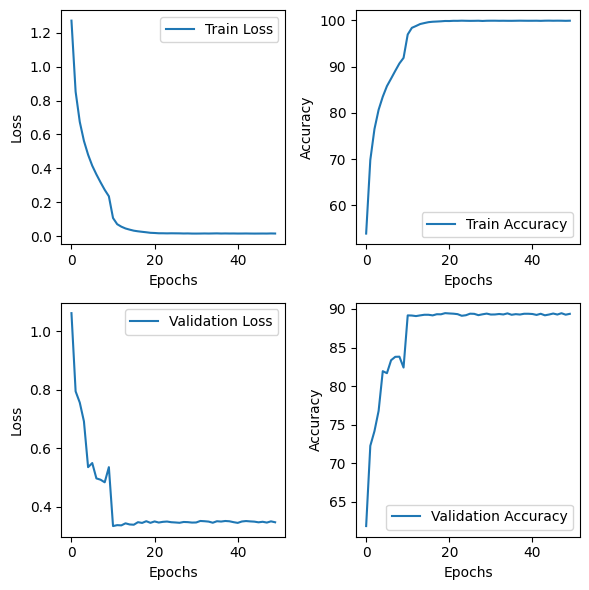

In [176]:
# Visualization of training and validation history

helper_plot_history(history_cnn, title_prefix="CNN classifier", savepath="./models/history_cnn.png")

### Execute testing

In [177]:
# Testing phase
## test_loss_total : loss calculated on total test samples for the current epoch
## test_sample_total : total number of test samples for the current epoch
## test_loss_mean_batch : loss calculated for the current test batch
## test_cnn_loss_epoch : calculate the average loss for the current epoch
## test_cnn_acc_epoch : calculate the accuracy for the current epoch
test_loss_total, test_sample_total = 0.0, 0.0
test_loss_mean_batch = 0.0

test_preds = []
act_preds = []

start_time = time.time()
with torch.no_grad():
    for batch_idx, (inputs, targets) in enumerate(test_loader):
        inputs, targets = inputs.to(device), targets.to(device)

        output_z = model_cnn_best(inputs) # input => MLP => output logits z

        test_loss_mean_batch = model_cnn_loss_func(output_z, targets)

        test_loss_total += test_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
        predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
        test_sample_total += targets.size(0)
        test_preds.append(predicted.to(device))
        act_preds.append(targets.to(device))

end_test_time = time.time()
result_cnn['test_time'] = end_test_time - start_time
result_cnn['test_loss'] = test_loss_total / test_sample_total
result_cnn['test_acc'] = accuracy_cnn(torch.cat(test_preds), torch.cat(act_preds))*100
cm_cnn(torch.cat(test_preds), torch.cat(act_preds))

print(f"[test_loss = {result_cnn['test_loss']:.4f}] [test_acc = {result_cnn['test_acc']:.2f}%]")

[test_loss = 0.3676] [test_acc = 88.60%]


### Evaluation

In [178]:
# Visualize model performance

helper_summary_performance(result_cnn, history_cnn)

Test Performance:
Test Accuracy: 88.5999984741211
Test Loss: 0.3675570288300514
Min loss of training set = 0.014326755198370665
Min loss of validation set = 0.33358393051624297
Max accuracy of training set = 99.9625
Max accuracy of validation set = 89.46
Train time = 0:0
Test time = 0:19


In [179]:
helper_replace2json(model_cnn_json_path, 'result', clean_for_json(result_cnn))
helper_replace2json(model_cnn_json_path, 'history', clean_for_json(history_cnn))

## [EVALUATION COMPARISION]

In [180]:
histories = [history_softmax, history_mlp, history_cnn]
predictions = [result_softmax, result_mlp, result_cnn]
confusionmatrixs = [cm_softmax, cm_mlp, cm_cnn]
model_names = ["Softmax", "MLP", "CNN"]

### Capacity/Training time

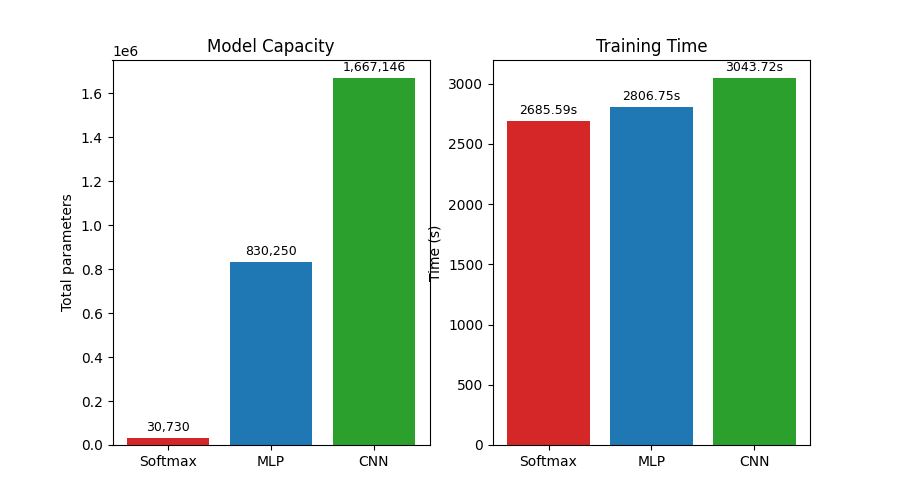

In [181]:
from IPython.display import Image, display

display(Image(filename='./models/cap_time_comparison.png'))

### Loss/Accuracy visualize

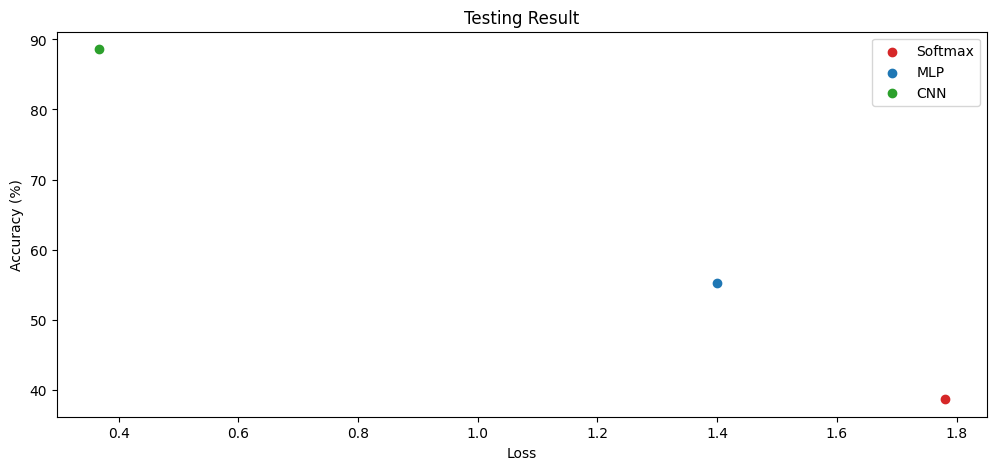

In [182]:
helper_plot_testing_result(predictions, model_names, savepath="./models/testing_result_accuracy.png")

### Loss-Accuracy curve

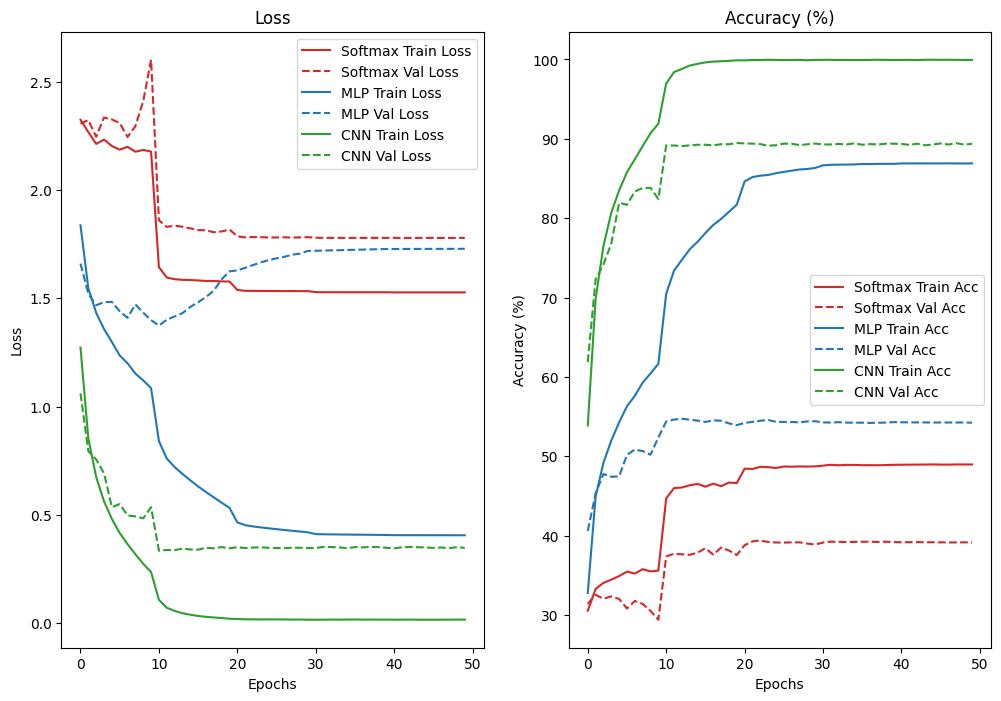

In [183]:
helper_plot_curves(histories, model_names, savepath="./models/curves.png")

### Confusion matrix

In [184]:
cm_pds = helper_extract_tp_tn_fp_fn(confusionmatrixs, predictions)

In [185]:
cm_pds

[   Class   TP    TN   FP   FN  precision  recall  F1_Score
 0      0  484  8385  615  516   0.440400   0.484  0.461172
 1      1  436  8453  547  564   0.443540   0.436  0.439738
 2      2  246  8431  569  754   0.301840   0.246  0.271074
 3      3  244  8275  725  756   0.251806   0.244  0.247842
 4      4  318  8346  654  682   0.327161   0.318  0.322515
 5      5  311  8358  642  689   0.326338   0.311  0.318484
 6      6  440  8314  686  560   0.390764   0.440  0.413923
 7      7  422  8448  552  578   0.433265   0.422  0.427558
 8      8  539  8424  576  461   0.483408   0.539  0.509693
 9      9  423  8429  571  577   0.425553   0.423  0.424273,
    Class   TP    TN   FP   FN  precision  recall  F1_Score
 0      0  642  8598  402  358   0.614943   0.642  0.628180
 1      1  637  8696  304  363   0.676939   0.637  0.656363
 2      2  454  8387  613  546   0.425492   0.454  0.439284
 3      3  380  8379  621  620   0.379620   0.380  0.379810
 4      4  452  8483  517  548   0.4664

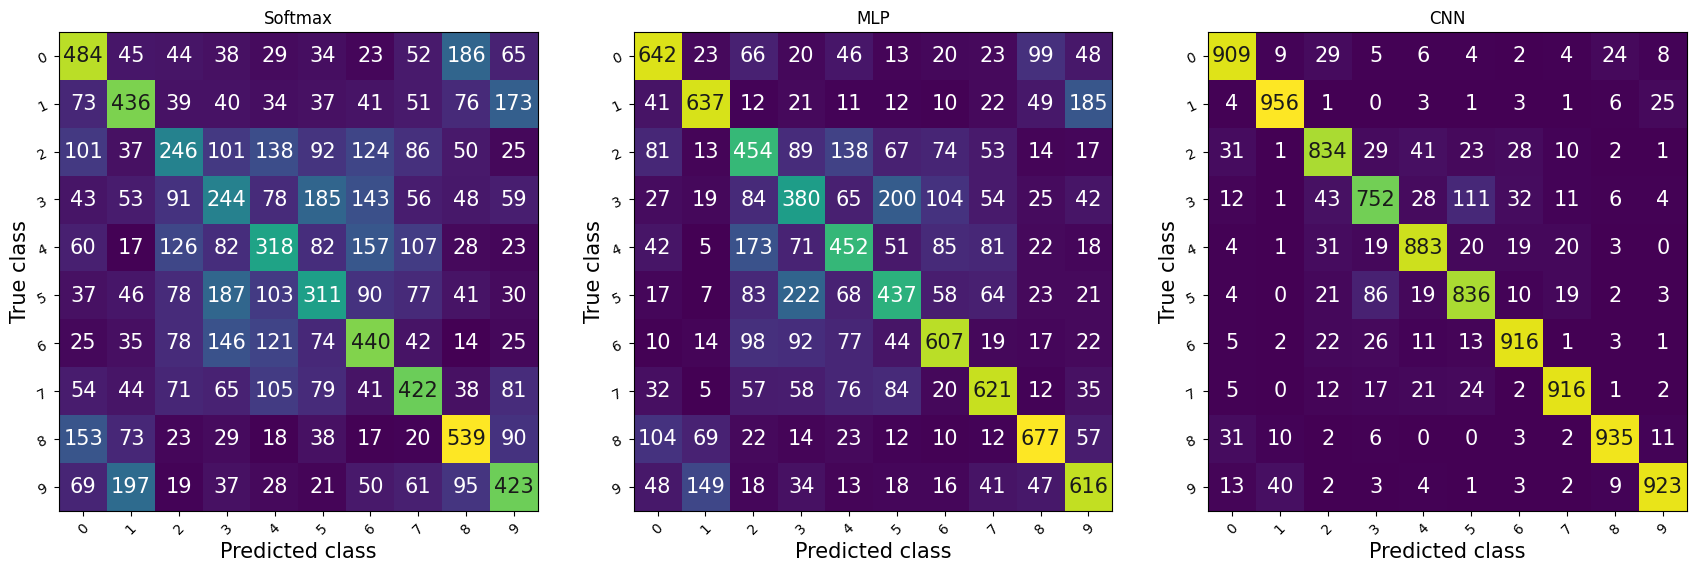

In [186]:
# Visualize both confusion matrix in one figure

helper_plot_cm(confusionmatrixs, model_names, savepath="./models/confusion_matrix.png")

### Save result

In [188]:
helper_replace2json(model_softmax_json_path, 'result', clean_for_json(result_softmax))
helper_replace2json(model_softmax_json_path, 'history', clean_for_json(history_softmax))
helper_replace2json(model_mlp_json_path, 'result', clean_for_json(result_mlp))
helper_replace2json(model_mlp_json_path, 'history', clean_for_json(history_mlp))
helper_replace2json(model_cnn_json_path, 'result', clean_for_json(result_cnn))
helper_replace2json(model_cnn_json_path, 'history', clean_for_json(history_cnn))

### Analyze fail prediction

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9843137..0.9764706].


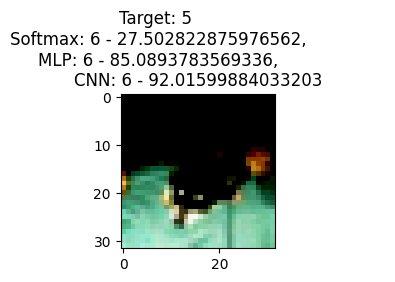

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.8352941..0.8980392].


Label: dog, Softmax: frog, MLP: frog, CNN: frog


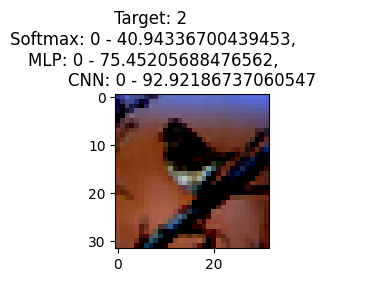

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.8509804..0.90588236].


Label: bird, Softmax: airplane, MLP: airplane, CNN: airplane


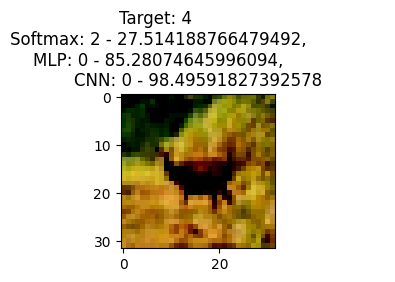

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9764706..1.0].


Label: deer, Softmax: bird, MLP: airplane, CNN: airplane


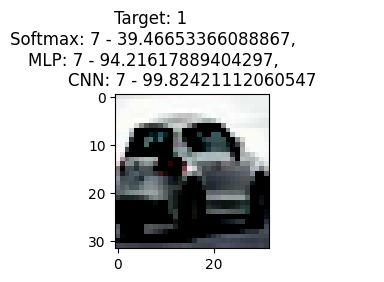

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9764706..1.0].


Label: automobile, Softmax: horse, MLP: horse, CNN: horse


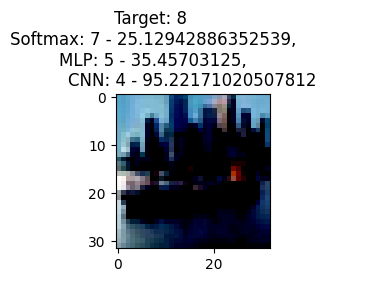

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9764706..0.9372549].


Label: ship, Softmax: horse, MLP: dog, CNN: deer


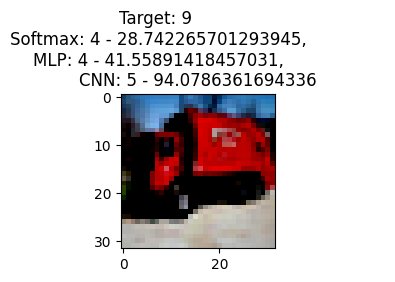

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.6627451..1.0].


Label: truck, Softmax: deer, MLP: deer, CNN: dog


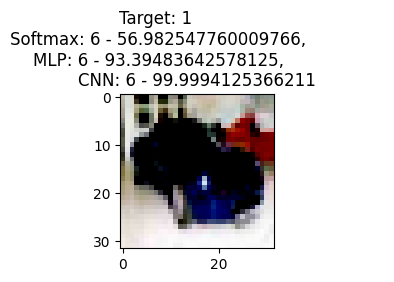

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.62352943..0.8980392].


Label: automobile, Softmax: frog, MLP: frog, CNN: frog


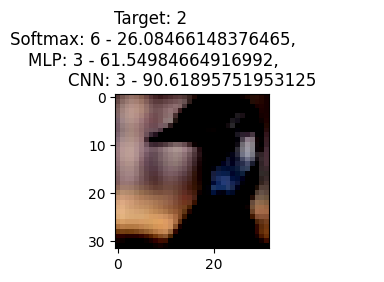

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


Label: bird, Softmax: frog, MLP: cat, CNN: cat


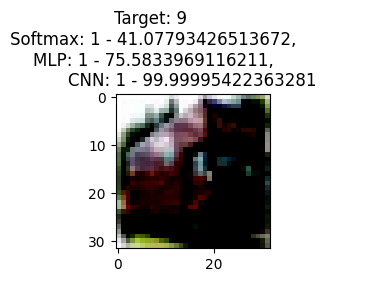

Label: truck, Softmax: automobile, MLP: automobile, CNN: automobile


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.85882354..0.9137255].


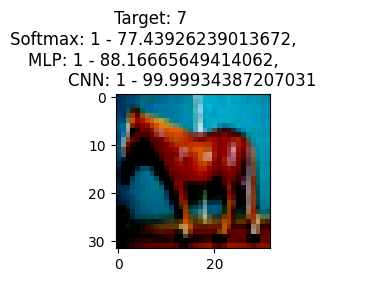

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.8901961..0.99215686].


Label: horse, Softmax: automobile, MLP: automobile, CNN: automobile


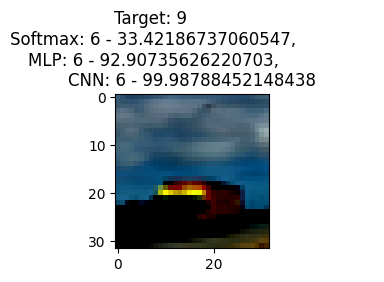

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.52156866..0.60784316].


Label: truck, Softmax: frog, MLP: frog, CNN: frog


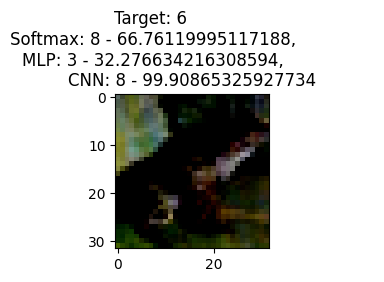

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.96862745..0.8745098].


Label: frog, Softmax: ship, MLP: cat, CNN: ship


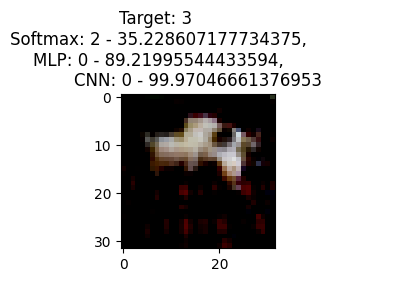

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.99215686..1.0].


Label: cat, Softmax: bird, MLP: airplane, CNN: airplane


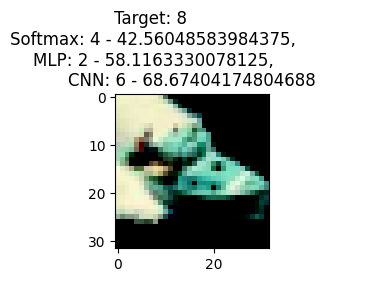

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.73333335..0.99215686].


Label: ship, Softmax: deer, MLP: bird, CNN: frog


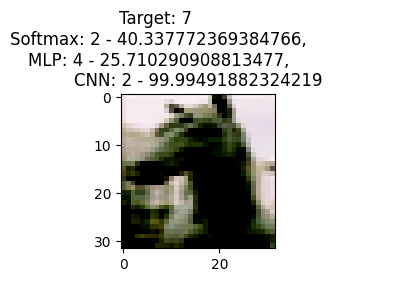

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.5764706].


Label: horse, Softmax: bird, MLP: deer, CNN: bird


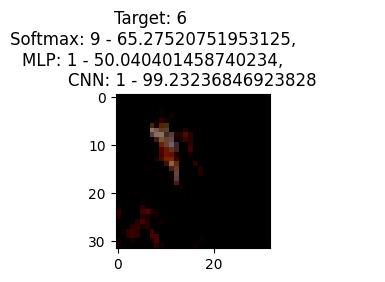

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9764706..1.0].


Label: frog, Softmax: truck, MLP: automobile, CNN: automobile


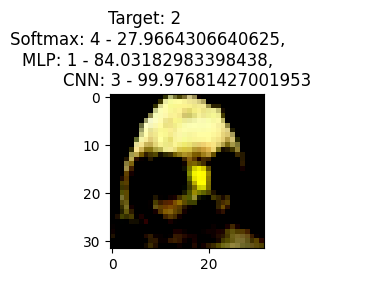

Label: bird, Softmax: deer, MLP: automobile, CNN: cat


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


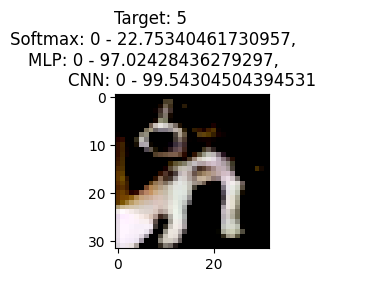

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.99215686..0.94509804].


Label: dog, Softmax: airplane, MLP: airplane, CNN: airplane


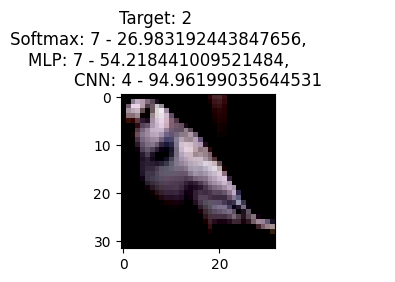

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


Label: bird, Softmax: horse, MLP: horse, CNN: deer


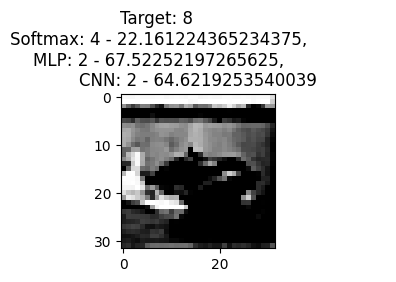

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


Label: ship, Softmax: deer, MLP: bird, CNN: bird


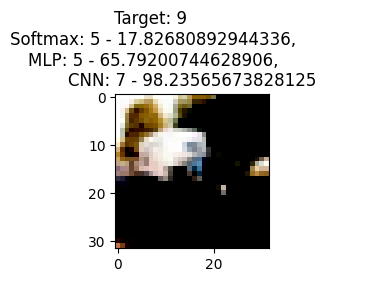

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.99215686..0.6156863].


Label: truck, Softmax: dog, MLP: dog, CNN: horse


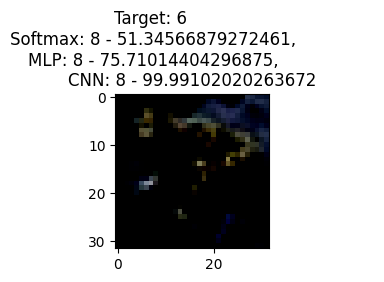

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9843137..0.8901961].


Label: frog, Softmax: ship, MLP: ship, CNN: ship


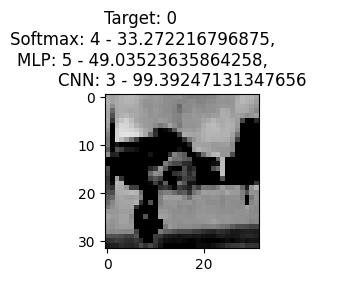

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9372549..0.99215686].


Label: airplane, Softmax: deer, MLP: dog, CNN: cat


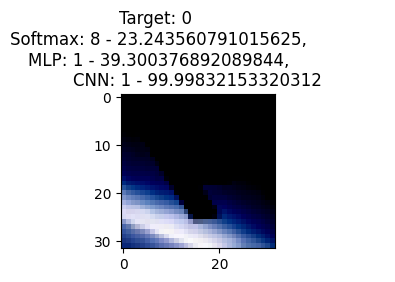

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.5921569..0.8666667].


Label: airplane, Softmax: ship, MLP: automobile, CNN: automobile


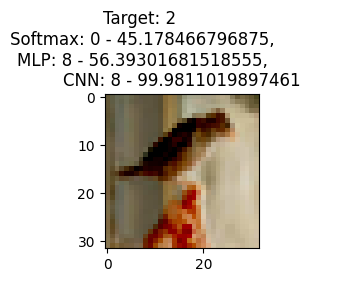

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.94509804..1.0].


Label: bird, Softmax: airplane, MLP: ship, CNN: ship


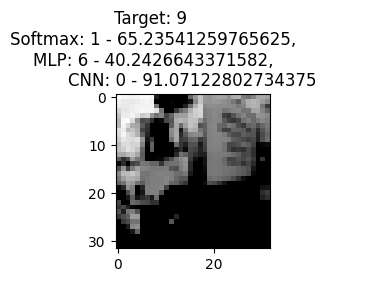

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.8745098..0.9137255].


Label: truck, Softmax: automobile, MLP: frog, CNN: airplane


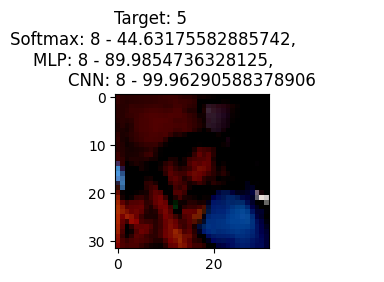

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.88235295..0.5921569].


Label: dog, Softmax: ship, MLP: ship, CNN: ship


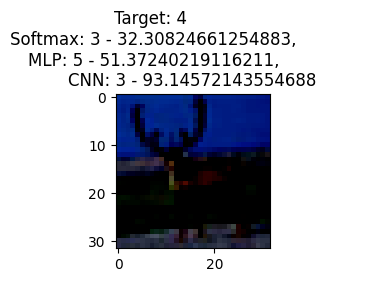

Label: deer, Softmax: cat, MLP: dog, CNN: cat


: 

In [ ]:
# get fail sampple from 3 models
import torch

torch.set_printoptions(precision=6, sci_mode=False)

with torch.no_grad():
    for batch_idx, (inputs, targets) in enumerate(test_loader):
        if batch_idx <= 3: # show the fail in specific batch
            inputs, targets = inputs.to(device), targets.to(device)

            # print(targets)
            out_softmax_logit = model_softmax_best(inputs)
            out_softmax_score = nn.LogSoftmax(dim=1)(out_softmax_logit).exp()*100
            out_softmax_labels = out_softmax_score.max(dim=1)[1]

            out_mlp_logit = model_mlp_best(inputs)
            out_mlp_score = nn.LogSoftmax(dim=1)(out_mlp_logit).exp()*100
            out_mlp_labels = out_mlp_score.max(dim=1)[1]

            out_cnn_logit = model_cnn_best(inputs)
            out_cnn_score = nn.LogSoftmax(dim=1)(out_cnn_logit).exp()*100
            out_cnn_labels = out_cnn_score.max(dim=1)[1]
        else:
            break
targets = targets.to(device)
inputs = inputs.to(device)
fail_mask = (out_softmax_labels != targets) & (out_mlp_labels != targets) & (out_cnn_labels != targets)
fail_inputs = inputs[fail_mask]
fail_targets = targets[fail_mask]
fail_out_softmax_labels = out_softmax_labels[fail_mask]
fail_out_mlp_labels = out_mlp_labels[fail_mask]
fail_out_cnn_labels = out_cnn_labels[fail_mask]
fail_out_softmax_score = out_softmax_score[fail_mask]
fail_out_mlp_score = out_mlp_score[fail_mask]
fail_out_cnn_score = out_cnn_score[fail_mask]

# print(fail_inputs)
# print(fail_targets)
# print(fail_out_softmax_labels)
# print(fail_out_mlp_labels)
# print(fail_out_cnn_labels)

# plot fail samples
import matplotlib.pyplot as plt

for i in range(len(fail_inputs)):
    plt.figure(figsize=(2,2))
    plt.imshow(fail_inputs[i].cpu().permute(1, 2, 0))
    plt.title(f"Target: {fail_targets[i].item()}\
                \nSoftmax: {fail_out_softmax_labels[i].item()} - {fail_out_softmax_score[i].max(dim=0)[0].cpu().item()},\
               \nMLP: {fail_out_mlp_labels[i].item()} - {fail_out_mlp_score[i].max(dim=0)[0].cpu().item()},\
               \nCNN: {fail_out_cnn_labels[i].item()} - {fail_out_cnn_score[i].max(dim=0)[0].cpu().item()}")
    plt.savefig(f"./models/fail_sample_{i}.png", dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Label: {global_class[fail_targets[i].item()]}, Softmax: {global_class[fail_out_softmax_labels[i].item()]}, MLP: {global_class[fail_out_mlp_labels[i].item()]}, CNN: {global_class[fail_out_cnn_labels[i].item()]}")